# Predictive maintenance: which devices will fail in the next week?

**Ahmad Hassan** | AI Engineer

A fleet of 1,169 devices reports nine anonymous telemetry readings once a day for ten months of 2015; 106 of them
fail. Maintenance can only act on a warning that comes **before** the failure, so the task here is a daily risk score:
from everything known about a device up to today, will it fail in the next 7 days? A crew would inspect the devices
with the highest scores each day.

**Result.** On devices the model never saw, a random forest flagged **15 of 26 failures** in the week before they
happened while raising about **0.8 alerts a day** for 291 devices; 31% of its alerts were real. A simple rule on the
failure counters caught the same 15 with 50% more alerts (21% real). The data holds a real but limited warning signal:
roughly a quarter of failures give no sign in these readings beforehand.

## What changed from the first version

- **It predicted nothing ahead of time.** The first version kept one row per device (its last day) and labelled it
  with that day's failure, so it "detected" failures from the readings of the failure day itself. Here each
  device-day is scored with data up to that day, against failure in the following 7 days.
- **Test devices leaked into training.** Scaling and random-forest feature selection were fitted on all devices
  before the split, and models were compared by their test-set scores. Here devices are split first (no device in both
  sets), models are chosen by cross-validation grouped by device, and the test devices are scored once.
- **The reported 0.98 came from a bug.** The final loop iterated `n_index` but used the leftover `train_index`, so it
  fitted and scored the same fold five times. The tuning loops never reset their score list (each point was a running
  mean over all earlier settings) and one plotted precision under the name "geo".
- **Wrong tools:** a random-forest *regressor* rounded into a classifier, XGBoost with a regression objective, and
  random oversampling (now class weights). The duplicate `attribute8` was dropped from the wrong table, so it stayed
  in the model; the text said under-sampling where the code over-sampled.
- **What the readings are.** Metrics 2, 3, 4, 5, 6, 7 and 9 never decrease: they are cumulative counters, and their
  *increases* carry the signal. The first version treated several of them as categories (278 one-hot columns for 1,169
  rows).

## 1. The data

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
SEED, H = 42, 7          # H: the warning window in days

raw = pd.read_csv("predictive_maintenance.csv", parse_dates=["date"], date_format="%m/%d/%y")
print(raw.shape, "| exact duplicate rows:", raw.duplicated().sum(), "| metric7 == metric8 everywhere:",
      (raw.metric7 == raw.metric8).all())
df = raw.drop_duplicates().drop(columns="metric8").sort_values(["device", "date"]).reset_index(drop=True)
print(f"{df.device.nunique()} devices, {df.date.min():%d %b} to {df.date.max():%d %b %Y}, "
      f"{df.failure.sum()} failures on {df[df.failure == 1].device.nunique()} devices")

(124494, 12) | exact duplicate rows: 1 | metric7 == metric8 everywhere: True
1169 devices, 01 Jan to 02 Nov 2015, 106 failures on 106 devices


In [2]:
last = df.groupby("device").date.max()
fails = df[df.failure == 1]
print("Failures on the device's last reported day:", (fails.date.values == fails.device.map(last).values).sum(), "of", len(fails))
print("Devices still reporting on the final day:", (last == df.date.max()).sum())
counters = ["metric2", "metric3", "metric4", "metric5", "metric6", "metric7", "metric9"]
steps = df.groupby("device")[counters + ["metric1"]].diff()
pd.DataFrame({"daily change < 0": (steps < 0).mean(), "daily change > 0": (steps > 0).mean(),
              "non-zero values": (df[counters + ["metric1"]] != 0).mean()}).round(3)

Failures on the device's last reported day: 101 of 106
Devices still reporting on the final day: 31


,daily change < 0,daily change > 0,non-zero values
metric2,0.000,0.007,0.051
metric3,0.000,0.000,0.073
metric4,0.000,0.002,0.075
metric5,0.000,0.003,1.000
metric6,0.000,0.405,1.000
metric7,0.000,0.001,0.012
metric9,0.000,0.001,0.218
metric1,0.386,0.602,1.000


A failed device usually stops reporting that day (101 of 106; five came back after repair). Most devices leave the
data long before the end without failing, so stopping is not itself a sign of failure. Every metric except `metric1`
only ever goes up: they are running counters. `metric6` rises on 41% of days (it behaves like hours of use); metrics
2, 4 and 7 rarely move at all.

## 2. Is there a warning before a failure?

In [3]:
F = df[df.failure == 1].groupby("device").date.min().rename("fdate")
m = df.join(F, on="device").dropna(subset=["fdate"])
m = m[m.date <= m.fdate].copy()
m["days_before"] = (m.fdate - m.date).dt.days
rows = {}
for c in ["metric2", "metric4", "metric7", "metric9"]:
    m["up"] = m.groupby("device")[c].diff().fillna(0) > 0
    week = m[m.days_before.between(1, H)]
    rows[c] = {"non-zero in the week before": (week.groupby("device")[c].max() > 0).sum(),
               "rose in the week before": week.groupby("device").up.any().sum(),
               "rose on the failure day": m[m.days_before == 0].up.sum()}
print(f"Failing devices with at least one day of history before the failure: {m[m.days_before >= 1].device.nunique()}")
pd.DataFrame(rows)

Failing devices with at least one day of history before the failure: 106


,metric2,metric4,metric7,metric9
non-zero in the week before,46,55,41,30
rose in the week before,34,32,22,4
rose on the failure day,21,23,10,0


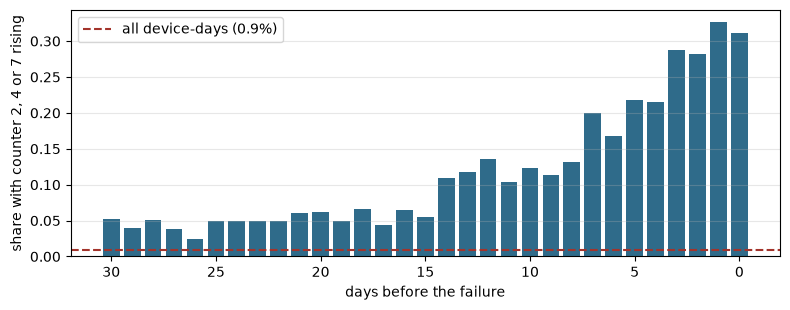

In [4]:
df["up247"] = (df.groupby("device")[["metric2", "metric4", "metric7"]].diff().fillna(0) > 0).any(axis=1)
m = m.merge(df[["device", "date", "up247"]], on=["device", "date"])
curve = m[m.days_before <= 30].groupby("days_before").up247.mean()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(curve.index, curve.values, color="#2f6b8a")
ax.axhline(df.up247.mean(), color="#a3332b", ls="--", label=f"all device-days ({df.up247.mean():.1%})")
ax.set_xlabel("days before the failure"); ax.set_ylabel("share with counter 2, 4 or 7 rising")
ax.invert_xaxis(); ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

Counters 2, 4 and 7 are already non-zero, or rising, in the week before most failures, far more often than on an
ordinary day. That is a usable warning. It is also incomplete: about a quarter of failing devices show nothing in
these counters beforehand, and plenty of devices have counter rises without failing.

## 3. One row per device-day, with only the past as features

Target: the device fails in the next 7 days (day *t*+1 to *t*+7). Rows after a device's first failure are dropped,
as are failure days themselves (nothing is left to warn about) and the last 7 days of the data (their outcome is
unknown).

In [5]:
first_fail = df[df.failure == 1].groupby("device").date.min()
df["fdate"] = df.device.map(first_fail)
df = df[df.fdate.isna() | (df.date <= df.fdate)].copy()
g = df.groupby("device")

COUNTERS = ["metric2", "metric3", "metric4", "metric7", "metric9"]
X = pd.DataFrame(index=df.index)
for c in COUNTERS:
    X[c] = np.log1p(df[c])
    for w in (1, 3, 7):
        X[f"{c}_up{w}d"] = (df[c] - g[c].shift(w).fillna(g[c].transform("first"))).clip(lower=0)
X["metric5"] = df.metric5
X["metric5_up7d"] = (df.metric5 - g.metric5.shift(7).fillna(g.metric5.transform("first"))).clip(lower=0)
X["metric6_log"] = np.log1p(df.metric6)
X["metric6_rate7d"] = (df.metric6 - g.metric6.shift(7)).fillna(0) / 7
X["metric1_log"] = np.log1p(df.metric1)
X["metric1_mean7d"] = np.log1p(g.metric1.transform(lambda s: s.rolling(7, min_periods=1).mean()))
X["metric1_std7d"] = np.log1p(g.metric1.transform(lambda s: s.rolling(7, min_periods=2).std()).fillna(0))
X["days_observed"] = (df.date - g.date.transform("min")).dt.days
for p in ["S1F0", "S1F1", "W1F0", "W1F1", "Z1F0", "Z1F1"]:
    X[f"family_{p}"] = df.device.str[:4].eq(p).astype(int)

days_to_fail = (df.fdate - df.date).dt.days
df["y"] = days_to_fail.between(1, H).astype(int)
keep = (days_to_fail.isna() | (days_to_fail >= 1)) & (df.date <= df.date.max() - pd.Timedelta(days=H))
X, meta = X[keep].reset_index(drop=True), df[keep].reset_index(drop=True)
y, groups = meta.y, meta.device
print(f"{X.shape[0]:,} device-days, {X.shape[1]} features; {y.sum()} in a failure week ({y.mean():.2%}), "
      f"from {meta[meta.y == 1].device.nunique()} failing devices")

124,185 device-days, 34 features; 712 in a failure week (0.57%), from 104 failing devices


Every feature uses the device's own past only: counter levels (log scale), how much each counter rose over the
last 1, 3 and 7 days, the usage rate of `metric6`, the recent level and variability of `metric1`, how long the device
has been observed, and its model family (the first four characters of the id).

## 4. Split by device

In [6]:
failing_device = meta.device.map(meta.groupby("device").fdate.first().notna()).astype(int)
tr, te = next(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED).split(X, failing_device, groups))
Xtr, ytr, gtr, ftr = X.iloc[tr], y.iloc[tr], groups.iloc[tr], failing_device.iloc[tr]
Xte, yte, mtr, mte = X.iloc[te], y.iloc[te], meta.iloc[tr].reset_index(drop=True), meta.iloc[te].reset_index(drop=True)
print(f"train: {gtr.nunique()} devices ({mtr[mtr.y == 1].device.nunique()} failing) | "
      f"test: {mte.device.nunique()} devices ({mte[mte.y == 1].device.nunique()} failing)")

train: 878 devices (78 failing) | test: 291 devices (26 failing)


## 5. Candidates, compared by cross-validation grouped by device

Class weights replace oversampling. The score that chooses is PR-AUC (average precision), which rewards ranking the
rare failure weeks above everything else; ROC-AUC is shown for reference. The baseline is a rule a maintenance team
could apply by hand: counter 2, 4 or 7 rose in the last 7 days (ranked first), or is non-zero.

In [7]:
def rule(Xp):
    return ((Xp[["metric2_up7d", "metric4_up7d", "metric7_up7d"]] > 0).any(axis=1).astype(float).values
            + 0.5 * (Xp[["metric2", "metric4", "metric7"]] > 0).any(axis=1).values)

pos_w = (ytr == 0).sum() / (ytr == 1).sum()
models = {
    "rule: counters 2/4/7": None,
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced", C=0.3)),
    "random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=20, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=50, subsample=0.8,
                               subsample_freq=1, colsample_bytree=0.8, scale_pos_weight=pos_w, random_state=SEED, verbose=-1),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=4, min_child_weight=5, subsample=0.8,
                             colsample_bytree=0.8, scale_pos_weight=pos_w, eval_metric="aucpr", random_state=SEED),
}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

def out_of_fold(model):
    p = np.zeros(len(ytr))
    for a, b in cv.split(Xtr, ftr, gtr):
        p[b] = rule(Xtr.iloc[b]) if model is None else model.fit(Xtr.iloc[a], ytr.iloc[a]).predict_proba(Xtr.iloc[b])[:, 1]
    return p

oof = {name: out_of_fold(m) for name, m in models.items()}
pd.DataFrame({name: {"PR-AUC": average_precision_score(ytr, p), "ROC-AUC": roc_auc_score(ytr, p)}
              for name, p in oof.items()}).T.round(3).sort_values("PR-AUC", ascending=False)

,PR-AUC,ROC-AUC
random forest,0.166,0.865
logistic regression,0.110,0.824
LightGBM,0.105,0.841
XGBoost,0.085,0.825
rule: counters 2/4/7,0.050,0.805


What a maintenance team sees is different from a ranking score: each day, the devices above a threshold get an
alert. A failure counts as **caught** if its device was alerted at least once in the 7 days before it failed.

In [8]:
def alerts(p, thr, m):
    alert = p >= thr
    week = (m.fdate - m.date).dt.days.between(1, H)
    return {"failures caught": f"{m[alert & week].device.nunique()}/{m[week].device.nunique()}",
            "alerts": int(alert.sum()), "alerts a day": round(alert.sum() / m.date.nunique(), 1),
            "alerts that were real": round((alert & week).sum() / max(alert.sum(), 1), 3)}

rows = []
for name, p in oof.items():
    for budget in (0.005, 0.01, 0.02):
        rows.append({"model": name, "alert on top": f"{budget:.1%}", **alerts(p, np.quantile(p, 1 - budget), mtr)})
pd.DataFrame(rows).set_index(["model", "alert on top"])

failures caught  alerts  alerts a day  \
model                alert on top                                         
rule: counters 2/4/7 0.5%                   49/78    2622           8.8   
                     1.0%                   49/78    2622           8.8   
                     2.0%                   49/78    2622           8.8   
logistic regression  0.5%                   32/78     466           1.6   
                     1.0%                   37/78     932           3.1   
                     2.0%                   46/78    1863           6.2   
random forest        0.5%                   39/78     466           1.6   
                     1.0%                   45/78     932           3.1   
                     2.0%                   51/78    1863           6.2   
LightGBM             0.5%                   29/78     466           1.6   
                     1.0%                   39/78     932           3.1   
                     2.0%                   48/78    1863           6.2   
XGBoost              0.5%                   22/78     466           1.6   
                     1.0%                   31/78     932           3.1   
                     2.0%                   42/78    1863           6.2   

                                   alerts that were real  
model                alert on top                         
rule: counters 2/4/7 0.5%                          0.092  
                     1.0%                          0.092  
                     2.0%                          0.092  
logistic regression  0.5%                          0.245  
                     1.0%                          0.165  
                     2.0%                          0.108  
random forest        0.5%                          0.309  
                     1.0%                          0.204  
                     2.0%                          0.130  
LightGBM             0.5%                          0.232  
                     1.0%                          0.166  
                     2.0%                          0.113  
XGBoost              0.5%                          0.172  
                     1.0%                          0.138  
                     2.0%                          0.100

The rule's score has only three values, so it cannot be tuned to a smaller alert budget: it raises about 9 alerts a
day to catch its failures, and fewer than one in ten is real. The random forest catches more failures at every alert
budget than the other models, and at 1% of device-days one alert in five is real.

## 6. Tuning the random forest (inside cross-validation)

In [9]:
grid = {}
for leaf in (5, 20, 50):
    for mf in ("sqrt", 0.5):
        m = RandomForestClassifier(n_estimators=400, min_samples_leaf=leaf, max_features=mf,
                                   class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
        p = out_of_fold(m)
        grid[(leaf, mf)] = (average_precision_score(ytr, p), p)
print(pd.Series({k: round(v[0], 3) for k, v in grid.items()}, name="CV PR-AUC").rename_axis(["min_samples_leaf", "max_features"]))
(leaf, mf), (best_ap, best_oof) = max(grid.items(), key=lambda kv: kv[1][0])
THRESHOLD = np.quantile(best_oof, 0.99)      # alert budget: the top 1% of device-days, fixed out of fold
print(f"chosen: min_samples_leaf={leaf}, max_features={mf}; alert threshold {THRESHOLD:.3f}")

min_samples_leaf  max_features
5                 sqrt            0.148
                  0.5             0.100
20                sqrt            0.166
                  0.5             0.118
50                sqrt            0.174
                  0.5             0.131
Name: CV PR-AUC, dtype: float64
chosen: min_samples_leaf=50, max_features=sqrt; alert threshold 0.662


## 7. The held-out devices, scored once

In [10]:
final = RandomForestClassifier(n_estimators=400, min_samples_leaf=leaf, max_features=mf,
                               class_weight="balanced_subsample", n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
p_test = final.predict_proba(Xte)[:, 1]
print(f"PR-AUC {average_precision_score(yte, p_test):.3f} | ROC-AUC {roc_auc_score(yte, p_test):.3f} "
      f"(a random score would give PR-AUC {yte.mean():.3f})")
pd.DataFrame({"random forest": alerts(p_test, THRESHOLD, mte), "rule: counters 2/4/7": alerts(rule(Xte), 1.0, mte)})

PR-AUC 0.262 | ROC-AUC 0.847 (a random score would give PR-AUC 0.006)


,random forest,rule: counters 2/4/7
failures caught,15/26,15/26
alerts,242,367
alerts a day,0.8,1.2
alerts that were real,0.306,0.21


On 291 unseen devices the forest caught 15 of 26 failures in their final week with about 0.8 alerts a day, against
1.2 a day for the rule, which caught the same 15. With 26 test failures, one or two either way changes these
percentages a lot; the cross-validation table above (78 failures) tells the same story with more data.

In [11]:
week = (mte.fdate - mte.date).dt.days.between(1, H)
lead = (mte[week & (p_test >= THRESHOLD)].groupby("device").apply(lambda d: (d.fdate - d.date).dt.days.max()))
print("Days of warning before each caught failure (first alert):", sorted(lead.astype(int).tolist(), reverse=True))

Days of warning before each caught failure (first alert): [7, 7, 7, 7, 7, 7, 7, 7, 5, 5, 5, 3, 2, 2, 2]


## 8. What drives the score

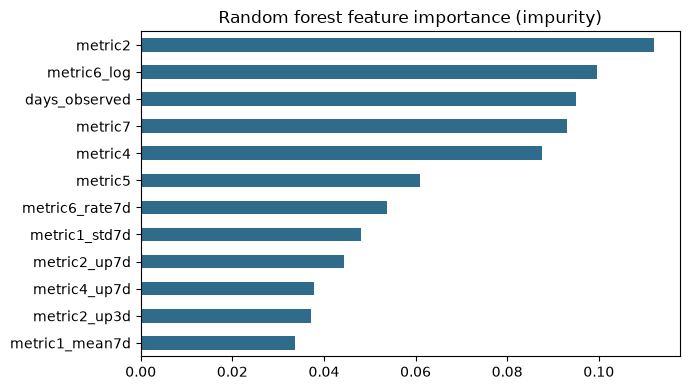

In [12]:
imp = pd.Series(final.feature_importances_, index=Xtr.columns).sort_values()
imp.tail(12).plot.barh(figsize=(7, 4), color="#2f6b8a", title="Random forest feature importance (impurity)")
plt.tight_layout(); plt.show()

The failure counters (2, 7, 4) and their recent rises dominate, with usage (`metric6`) and how long the device has
been watched. Impurity importance favours features with many distinct values, so it is a rough guide, not a ranking
to rely on.

## Conclusions

- **A 7-day warning is possible for about half to 60% of failures**, at a cost of roughly one alert a day per 300
  devices; one alert in three to five points at a device that really fails that week.
- **The random forest's gain over a hand rule is in false alarms, not in failures caught**: the counters carry most
  of the signal, and the model mainly learns which counter rises matter for which devices.
- **The rest of the failures give no warning in these nine readings.** More useful data (maintenance logs, error
  codes, sensor names and units) would help more than a more complex model.

**Limits.** 106 failures (26 in the test devices) is very little; the readings are anonymous, so features cannot be
designed from engineering knowledge; the alert budget (top 1% of device-days) is an assumption that should come
from the real cost of an inspection against the cost of a failure.